In [1]:
!pip uninstall -y massi
!pip cache purge

Found existing installation: massi 0.1.0
Uninstalling massi-0.1.0:
  Successfully uninstalled massi-0.1.0
Files removed: 6 (1.2 MB)


In [2]:
!cd .. && pip install -v . --group=dev --group=observability --group=sandbox

Using pip 25.3 from /opt/conda/lib/python3.13/site-packages/pip (python 3.13)
Processing /home/jovyan/work
  Running command installing build dependencies
  Using pip 25.3 from /opt/conda/lib/python3.13/site-packages/pip (python 3.13)
    Obtaining dependency information for setuptools>=40.8.0 from https://files.pythonhosted.org/packages/9d/76/f789f7a86709c6b087c5a2f52f911838cad707cc613162401badc665acfe/setuptools-82.0.1-py3-none-any.whl.metadata
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/1.0 MB ? eta -:--:--
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/1.0 MB ? eta -:--:--
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/1.0 MB ? eta -:--:--
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/1.0 MB ? eta -:--:--
     ━━━━━━━━━━╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.3/1.0 MB ? eta -:--:--
     ━━━━━━━━━━╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.3/1.0 MB ? eta -:--:--
     ━━━━━━━━━━━━━━━━━━━━╸━━━━━━━━━━━━━━━━━━━ 0.5/1.0 MB 504.3 kB/s eta 0:00:01
     ━━━━━━━━━━━━━━━━━━━━╸━━━━━━━━━━━━━━━━━

In [3]:
# Setup observability
USE_OBSERVABILITY = True

if USE_OBSERVABILITY:
    import os
    from lmnr import Laminar
    
    Laminar.initialize(
        project_api_key=os.environ["LMNR_PROJECT_API_KEY"],
        base_url=f"http://{os.environ["HOST_MACHINE_URL_CORE"]}",
        http_port=int(os.environ["LMNR_PROJECT_HTTP_PORT"]),
        grpc_port=int(os.environ["LMNR_PROJECT_GRPC_PORT"]),
    )
    print("Observability is ready")

Observability is ready


In [4]:
import lmnr
lmnr.version

<module 'lmnr.version' from '/opt/conda/lib/python3.13/site-packages/lmnr/version.py'>

In [5]:
from massi.agents.massi import Config

In [6]:
from massi.agents.massi import create_ollama_llm

base_config = Config(**{"model_url": "http://host.docker.internal:11434", "model_name": "granite4:3b"})
base_llm_client=create_ollama_llm(base_config)

In [7]:
from massi.agents.massi import create_openai_llm
openai_config = Config(**{"api_key": os.environ["OPENAI_API_TOKEN"], "model_name": "gpt-5.4-nano"})
openai_llm_client = create_openai_llm(openai_config)

In [8]:
USE_OPEN_AI = True

print(">>> Using OpenAI") if USE_OPEN_AI else print(">>> Using Ollama")
main_llm = openai_llm_client if USE_OPEN_AI else base_llm_client

>>> Using OpenAI


# Starting the DWC-ready massi

In [9]:
import massi.agents.workflow as mw 

In [10]:
from langchain_core.messages import HumanMessage 

class LocalMetadataArchitect(mw.MetadataArchitect):
    def __init__(self, llm_client):
        self._client = llm_client

    def invoke(self, prompt: str) -> mw.MetadataBlueprint:
        return self._client.with_structured_output(mw.MetadataBlueprint).invoke([HumanMessage(content=prompt)])


class LocalMetadataBlueprintReviewer(mw.MetadataBlueprintReviewer):
    def __init__(self, llm_client):
        self._client = llm_client

    def invoke(self, prompt: str) -> mw.MetadataGapDerivationPlan:
        return self._client.with_structured_output(mw.MetadataGapDerivationPlan).invoke([HumanMessage(content=prompt)])

In [11]:
import massi.agents.sub_agents.data_explorer as de

In [27]:
class LocalMetadataGapDerivationManager(mw.MetadataGapDerivationManager):
    # THIS MUST BE IMPROVED
    def invoke(self, task: mw.MetadataGapTask, execution_mode: mw.MassiExecutionMode, architect_prompt: str, xml_blueprint: str) -> str:
        return task["gap_derivation_request"]

# MetadataGapDerivationExecutor
class LocalMetadataGapDerivationExecutor(mw.MetadataGapDerivationExecutor):
    def __init__(self, llm_client):
        self._agent = de.DataExplorerAgent(llm_client)

    def invoke(self, prompt: str, task: mw.MetadataGapTask) -> mw.MetadataGapTaskOutcome:
        request = {"instruction": prompt, "file_paths": task["gap_scope_files"]}
        result = self._agent.invoke(request)
        return {"result": str(result["final_output"].content), "task": task}

# MetadataGapPatcher
class LocalMetadataGapPatcher(mw.MetadataGapPatcher): 
    def invoke(self, outcome: mw.MetadataGapTaskOutcome, blueprint: mw.MetadataBlueprint) -> mw.MetadataBlueprint:
        outcome_content = outcome["result"]["content"]
        print(outcome_content)
        gap_replacement_tag = outcome["task"]["gap_replacement_pattern"]
        print(gap_replacement_tag)
        patched_content = blueprint["content"].replace(gap_replacement_tag, outcome_content)
        return {**blueprint, "content": patched_content}

In [28]:
resolution_dependencies = mw.Dependencies(
    execution_mode=mw.MassiExecutionMode.HUMAN_INQUIRY,
    
    architect_client=LocalMetadataArchitect(main_llm),
    reviewer_client=LocalMetadataBlueprintReviewer(main_llm),
    gap_derivation_manager_client=LocalMetadataGapDerivationManager(),
    data_explorer_client=LocalMetadataGapDerivationExecutor(main_llm),
    author_interviewer_client=LocalMetadataGapDerivationExecutor(main_llm),
    metadata_gap_patcher_client=LocalMetadataGapPatcher(),
)

In [29]:
goal_workflow = mw._build_goal_resolution_graph(resolution_dependencies)

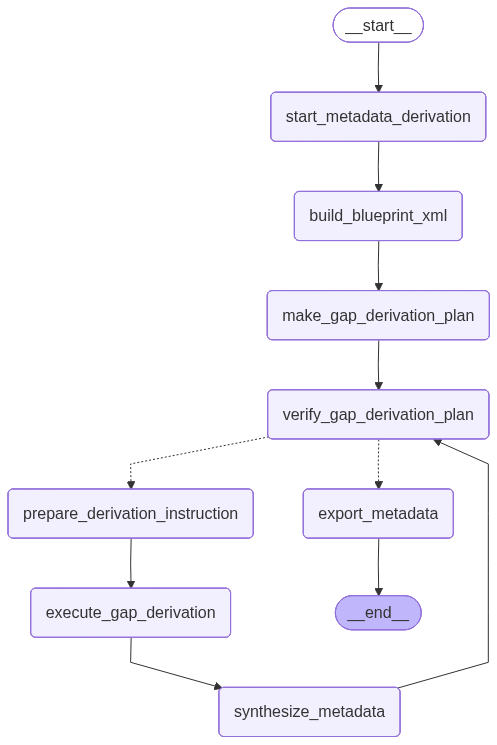

In [30]:
goal_workflow.graph

In [31]:
core_dependencies = mw.Dependencies(
    execution_mode=mw.MassiExecutionMode.HUMAN_INQUIRY,
    
    architect_client=LocalMetadataArchitect(main_llm),
    reviewer_client=LocalMetadataBlueprintReviewer(main_llm),
    gap_derivation_manager_client=LocalMetadataGapDerivationManager(),
    data_explorer_client=LocalMetadataGapDerivationExecutor(main_llm),
    author_interviewer_client=LocalMetadataGapDerivationExecutor(main_llm),
    metadata_gap_patcher_client=LocalMetadataGapPatcher(),
    
    metadata_resolution_subgraph=goal_workflow
)

In [32]:
core_workflow = mw.build_graph(core_dependencies)

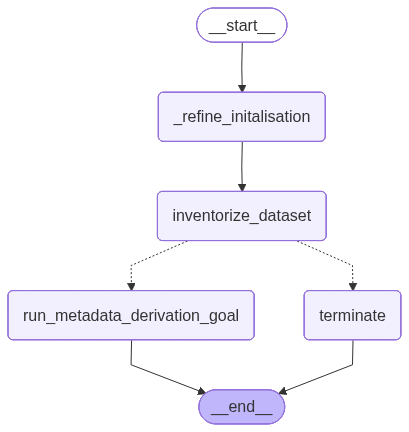

In [33]:
core_workflow.graph

## Inference

In [19]:
import massi.agents.tools as mt

In [20]:
dwc_data_file_metadata_goal: mw.MetadataGoal = {
    "level": mw.MetadataLevel.ITEM,
    "scopes": [mw.MetadataScope.DESCRIPTIVE, mw.MetadataScope.TECHNICAL, mw.MetadataScope.USE],
    "target_filename": "meta.xml",
    "schema_source": "https://dwc.tdwg.org/text/tdwg_dwc_text.xsd",
    "description": (
        "This metadata file describes the archive and data file structure."
        "A descriptor metafile describes how the files in your archive are organized."
        "It describes the files in the archive and maps each data column to a corresponding standard Darwin Core or Extension term."
        "The metafile is a relatively simple XML file format."
    ),
    "metadata_goal_key": "darwin_core",
}

In [21]:
print(mt.get_xmlschema_validator(dwc_data_file_metadata_goal["schema_source"]).to_string())

/opt/conda/lib/python3.13/site-packages/xmlschema/loaders.py:312: XMLSchemaImportWarning: Import of namespace 'http://purl.org/dc/terms/' from ['http://dublincore.org/schemas/xmls/qdc/2008/02/11/dcterms.xsd'] failed: can't access to resource 'http://dublincore.org/schemas/xmls/qdc/2008/02/11/dcterms.xsd': Forbidden.
  return self.schema_class(
/opt/conda/lib/python3.13/site-packages/xmlschema/loaders.py:312: XMLSchemaImportWarning: Import of namespace 'http://purl.org/dc/elements/1.1/' from ['http://dublincore.org/schemas/xmls/qdc/dc.xsd'] failed: can't access to resource 'http://dublincore.org/schemas/xmls/qdc/dc.xsd': Forbidden.
  return self.schema_class(


<xs:schema xmlns:xs="http://www.w3.org/2001/XMLSchema" version="0.1" targetNamespace="http://rs.tdwg.org/dwc/text/" attributeFormDefault="unqualified" elementFormDefault="qualified">
    <xs:import namespace="http://rs.tdwg.org/dwc/terms/" schemaLocation="https://raw.githubusercontent.com/tdwg/dwc/master/docs/xml/tdwg_dwcterms.xsd" />
    <xs:import namespace="http://www.w3.org/XML/1998/namespace" schemaLocation="http://rs.gbif.org/schema/xml.xsd">
        <xs:annotation>
            <xs:documentation>
                Get access to the xml: attribute groups for xml:lang
            </xs:documentation>
        </xs:annotation>
    </xs:import>
    
    
    <xs:element name="archive">
        <xs:complexType>
            <xs:sequence>
                <xs:element name="core" type="arch:coreFileType" maxOccurs="1" minOccurs="1" />
                <xs:element name="extension" type="arch:extensionFileType" maxOccurs="unbounded" minOccurs="0" />
            </xs:sequence>
            <xs:att

In [22]:
dwc_eml_metadata_goal: mw.MetadataGoal = {
    "level": mw.MetadataLevel.COLLECTION,
    "scopes": [
        mw.MetadataScope.DESCRIPTIVE,
        mw.MetadataScope.ADMINISTRATIVE,
        mw.MetadataScope.PRESERVATION,
        mw.MetadataScope.USE,
    ],
    "target_filename": "eml.xml",
    "schema_source": "https://eml.ecoinformatics.org/eml-2.2.0/eml.xsd",
    "description": (
        "This metadata file contains the dataset's aggregate metadata."
        "This is a resource metadata document that provides information about the dataset itself such as a description (abstract) of the dataset, the agents responsible for authorship, publication and documentation, bibliographic and citation information, collection methods and much more."
        "It is based on the Ecological Metadata Language."
    ),
    "metadata_goal_key": "eml",
}

In [23]:
print(mt.get_xmlschema_validator(dwc_eml_metadata_goal["schema_source"]).to_string())

<xs:schema xmlns:doc="https://eml.ecoinformatics.org/documentation-2.2.0" xmlns:xs="http://www.w3.org/2001/XMLSchema" targetNamespace="https://eml.ecoinformatics.org/eml-2.2.0">
    <xs:import namespace="https://eml.ecoinformatics.org/documentation-2.2.0" schemaLocation="eml-documentation.xsd" />
    <xs:import namespace="https://eml.ecoinformatics.org/dataset-2.2.0" schemaLocation="eml-dataset.xsd" />
    <xs:import namespace="https://eml.ecoinformatics.org/literature-2.2.0" schemaLocation="eml-literature.xsd" />
    <xs:import namespace="https://eml.ecoinformatics.org/software-2.2.0" schemaLocation="eml-software.xsd" />
    <xs:import namespace="https://eml.ecoinformatics.org/protocol-2.2.0" schemaLocation="eml-protocol.xsd" />
    <xs:import namespace="https://eml.ecoinformatics.org/resource-2.2.0" schemaLocation="eml-resource.xsd" />
    <xs:import namespace="https://eml.ecoinformatics.org/access-2.2.0" schemaLocation="eml-access.xsd" />
    <xs:import namespace="https://eml.ecoinf

In [24]:
import random

In [36]:
thread_config = {"configurable": {"thread_id": str(random.randint(1, 100))}}

base_state: mw.MassiCoreState = {
    "settings": {
        "runtime_config": {
            "working_directory": "./dwc_data/masked-doi-10.34894-72gq4c", 
            "output_directory": "./dwc_data/masked-doi-10.34894-72gq4c"
        },
        "execution_mode": mw.MassiExecutionMode.HUMAN_INQUIRY
    },
    # "goals": [dwc_data_file_metadata_goal, dwc_eml_metadata_goal]
    "goals": [dwc_data_file_metadata_goal]
}

In [ ]:
outcome = core_workflow.graph.invoke(base_state, thread_config)

/opt/conda/lib/python3.13/site-packages/xmlschema/loaders.py:312: XMLSchemaImportWarning: Import of namespace 'http://purl.org/dc/terms/' from ['http://dublincore.org/schemas/xmls/qdc/2008/02/11/dcterms.xsd'] failed: can't access to resource 'http://dublincore.org/schemas/xmls/qdc/2008/02/11/dcterms.xsd': Forbidden.
  return self.schema_class(
/opt/conda/lib/python3.13/site-packages/xmlschema/loaders.py:312: XMLSchemaImportWarning: Import of namespace 'http://purl.org/dc/elements/1.1/' from ['http://dublincore.org/schemas/xmls/qdc/dc.xsd'] failed: can't access to resource 'http://dublincore.org/schemas/xmls/qdc/dc.xsd': Forbidden.
  return self.schema_class(


In [ ]:
from pprint import pprint

In [ ]:
print(outcome["resolutions"][0]["architect_xml_blueprint"]["content"])

In [ ]:
pprint(outcome["resolutions"][0]["gap_derivation_plan"])

In [ ]:
print(outcome["resolutions"][0]["working_copy_xml_blueprint"]["content"])